<img src="https://www.th-koeln.de/img/logo.svg" style="float:right;" width="200">

# 4th exercise: <font color="#C70039">Use Isolation Forest for anomaly detection</font>
* Course: AML
* Lecturer: <a href="https://www.gernotheisenberg.de/">Gernot Heisenberg</a>
* Author of notebook: <a href="https://www.gernotheisenberg.de/">Gernot Heisenberg</a>
* Date:   10.11.2026
* Student Name : Mohammed Suhan, Mohammed Suhan
* Matriculation No. : 11707086

<img src="https://upload.wikimedia.org/wikipedia/commons/c/ce/Isolating_a_Non-Anomalous_Point.png" style="float: center;" width="450">

---------------------------------
**GENERAL NOTE 1**: 
Please make sure you are reading the entire notebook, since it contains a lot of information on your tasks (e.g. regarding the set of certain parameters or a specific computational trick), and the written mark downs as well as comments contain a lot of information on how things work together as a whole. 

**GENERAL NOTE 2**: 
* Please, when commenting source code, just use English language only. 
* When describing an observation please use English language, too
* This applies to all exercises throughout this course.  

---------------------

### <font color="ce33ff">DESCRIPTION</font>:
This notebook allows you for using the Isolation Forest algorithm for anomaly detection. Isolation Forest is an unsupervised learning algorithm that belongs to the ensemble decision trees family. The following <a href="https://cs.nju.edu.cn/zhouzh/zhouzh.files/publication/icdm08b.pdf">paper</a> explains the details on its theory and implementation. 

-------------------------------------------------------------------------------------------------------------

### <font color="FFC300">TASKS</font>:
The tasks that you need to work on within this notebook are always indicated below as bullet points. 
If a task is more challenging and consists of several steps, this is indicated as well. 
Make sure you have worked down the task list and commented your doings. 
This should be done by using markdown.<br> 
<font color=red>Make sure you don't forget to specify your name and your matriculation number in the notebook.</font>

**YOUR TASKS in this exercise are as follows**:
1. import the notebook to Google Colab or use your local machine.
2. make sure you specified your name and your matriculation number in the header below my name and date. 
    * set the date too and remove mine.
3. read the entire notebook carefully 
    * add comments wherever you feel it necessary for better understanding
    * run the notebook for the first time. 

4. take the three data sets from exercise 1 and apply the isolation forest to them.
5. implement an appropriate visualisation (chart) that renders the result (anomaly={yes,no}) for every data point TOGETHER with the original data point in your data set.
-----------------------------------------------------------------------------------

### First example

In [7]:
# Google Colab setup: make repository files available under the expected relative paths.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    repository = "/content/AML"
    if not os.path.isdir(repository):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/gheisenberg/AML.git", repository], check=True)
    os.chdir(repository)

In [8]:
# Import the Isolation Forest estimator and create a reproducible two-feature data set.
# Each row of random_data is one observation that the model can isolate.
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

rng = np.random.default_rng(1)
random_data = rng.normal(loc=20.0, scale=20.0, size=(50_000, 2))

This code will output the predictions for each data point in an array. If the result is -1, it means that this specific data point is an outlier. If the result is 1, then it means that the data point is not an outlier.

In [9]:
# fit_predict trains the forest and immediately returns one label per observation.
# A label of -1 means outlier; a label of 1 means inlier.
# Fit the estimator and return one label per training observation.
isolation_forest_1 = IsolationForest(
    max_samples=100,
    contamination="auto",
    random_state=1,
    n_jobs=-1,
)
outlier_labels = isolation_forest_1.fit_predict(random_data)

print(outlier_labels[:200])
print(f"Detected outliers: {np.count_nonzero(outlier_labels == -1)}")

[ 1  1  1  1  1  1  1  1  1  1  1  1 -1  1  1 -1 -1  1 -1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1  1 -1  1  1  1  1  1 -1
  1  1  1  1  1 -1 -1  1  1  1  1  1 -1 -1 -1  1  1  1  1  1  1  1 -1  1
  1  1  1  1  1 -1  1 -1  1  1  1 -1  1  1  1 -1  1  1  1 -1  1  1  1  1
 -1  1  1  1 -1  1  1 -1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1
  1  1 -1  1  1  1  1  1  1  1  1 -1  1  1  1  1 -1  1  1 -1  1  1  1  1
  1  1  1  1  1 -1  1  1  1  1  1 -1  1  1  1 -1  1  1  1  1  1  1  1  1
 -1 -1  1  1  1  1  1 -1  1  1  1  1  1  1  1  1  1 -1  1 -1  1  1  1  1
  1  1  1  1  1 -1  1  1]
Detected outliers: 13560


### Second example

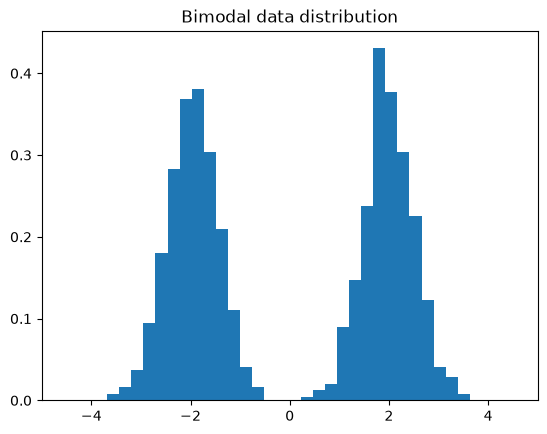

In [10]:
# Build two dense groups so low-density regions are easy to interpret visually.
# The following histogram is the reference distribution for the anomaly model.
# Create and visualize a bimodal data distribution.
bimodal_data = np.concatenate(
    (
        rng.normal(loc=-2.0, scale=0.5, size=500),
        rng.normal(loc=2.0, scale=0.5, size=500),
    )
)

plt.hist(bimodal_data, bins=30, density=True)
plt.xlim(-5, 5)
plt.title("Bimodal data distribution")
plt.show()

Note, that there are three regions where the data has low probability to appear: 
* one on the right side of the distribution
* another one on the left
* and another around zero. 

Let's see if the IsolationForest is able to identify these three regions

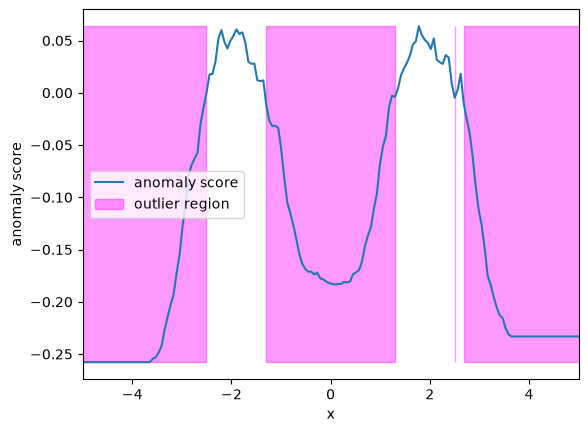

In [11]:
# Evaluate anomaly scores on a regular grid instead of only on training points.
# This makes the predicted outlier regions visible on the plot.
# Fit a reproducible Isolation Forest with 100 estimators.
isolation_forest_2 = IsolationForest(n_estimators=100, random_state=1)
isolation_forest_2.fit(bimodal_data.reshape(-1, 1))

# Evaluate the anomaly score over a regular grid on the x-axis.
score_grid = np.linspace(-6, 6, 200).reshape(-1, 1)
anomaly_score = isolation_forest_2.decision_function(score_grid)
outlier_labels = isolation_forest_2.predict(score_grid)

plt.plot(score_grid[:, 0], anomaly_score, label="anomaly score")
plt.fill_between(
    score_grid[:, 0],
    anomaly_score.min(),
    anomaly_score.max(),
    where=outlier_labels == -1,
    color="#FF00FF",
    alpha=0.4,
    label="outlier region",
)
plt.legend()
plt.ylabel("anomaly score")
plt.xlabel("x")
plt.xlim(-5, 5)
plt.show()

## Isolation Forest on my three data sets
I reuse the three data sets from the previous exercises: Bundesliga heights, IPL first-innings totals and F1 lap times (2024 Italian Grand Prix).

In [12]:
import pandas as pd
import kagglehub
from scipy import stats

# Download (cached from Exercise 1)
fifa_path = kagglehub.dataset_download("stefanoleone992/fifa-22-complete-player-dataset")
ipl_path = kagglehub.dataset_download("patrickb1912/ipl-complete-dataset-20082020")
f1_path = kagglehub.dataset_download("rohanrao/formula-1-world-championship-1950-2020")

# 1) Bundesliga heights
players = pd.read_csv(os.path.join(fifa_path, "players_22.csv"), low_memory=False)
heights = players.loc[players["league_name"] == "German 1. Bundesliga", "height_cm"].dropna().astype(float).to_numpy()

# 2) IPL first-innings totals (full 20-over matches, no rain rule)
matches = pd.read_csv(os.path.join(ipl_path, "matches.csv"))
full_matches = matches[(matches["target_overs"] == 20) & (matches["method"].isna())]
ipl_totals = (full_matches["target_runs"].dropna() - 1).astype(float).to_numpy()

# 3) F1 lap times, 2024 Italian Grand Prix (raceId 1136)
RACE_ID = 1136
lap_times = pd.read_csv(os.path.join(f1_path, "lap_times.csv"))
drivers = pd.read_csv(os.path.join(f1_path, "drivers.csv"))
pit_stops = pd.read_csv(os.path.join(f1_path, "pit_stops.csv"))

laps = lap_times[lap_times["raceId"] == RACE_ID].merge(drivers[["driverId", "code"]], on="driverId")
laps["lap_s"] = laps["milliseconds"] / 1000

# Pit-stop time is counted in the lap after the stop, so shift by one
race_pits = pit_stops[pit_stops["raceId"] == RACE_ID][["driverId", "lap"]]
race_pits["lap"] = race_pits["lap"] + 1
race_pits["pit_lap"] = True
laps = laps.merge(race_pits, on=["driverId", "lap"], how="left")
laps["pit_lap"] = laps["pit_lap"].eq(True)

lap_seconds = laps["lap_s"].to_numpy()

datasets = {
    "Bundesliga height (cm)": heights,
    "IPL first-innings total (runs)": ipl_totals,
    "F1 Monza 2024 lap time (s)": lap_seconds,
}

for name, values in datasets.items():
    print(f"{name}: {values.size} values")

Bundesliga height (cm): 551 values
IPL first-innings total (runs): 1062 values
F1 Monza 2024 lap time (s): 1008 values


In [13]:
from sklearn.ensemble import IsolationForest

if_labels = {}
if_scores = {}

for name, values in datasets.items():
    X = values.reshape(-1, 1)
    model = IsolationForest(n_estimators=100, contamination="auto", random_state=1)
    if_labels[name] = model.fit_predict(X)        # -1 = anomaly, 1 = normal
    if_scores[name] = model.decision_function(X)  # lower = more anomalous

    n_anom = np.sum(if_labels[name] == -1)
    print(f"{name}: {n_anom} anomalies ({n_anom / values.size:.2%})")

Bundesliga height (cm): 188 anomalies (34.12%)
IPL first-innings total (runs): 209 anomalies (19.68%)
F1 Monza 2024 lap time (s): 167 anomalies (16.57%)


### Choosing the cutoff
The default (`contamination="auto"`) flags every point with an anomaly score s > 0.5. On my data this marks 16 to 34% of all points as anomalies, which is unrealistic. The lecture defines s ≈ 1 as anomalous and s ≈ 0.5 as a regular point . I therefore only flag points with s > 0.6, which are clearly closer to 1 than to 0.5.

In [14]:
S_CUTOFF = 0.6

if_s = {}
if_anom = {}

for name, values in datasets.items():
    X = values.reshape(-1, 1)
    model = IsolationForest(n_estimators=100, random_state=1).fit(X)

    # score_samples returns -s, so flip the sign to get the score from the slides
    if_s[name] = -model.score_samples(X)
    if_anom[name] = if_s[name] > S_CUTOFF

    n_anom = if_anom[name].sum()
    print(f"{name}: s from {if_s[name].min():.2f} to {if_s[name].max():.2f}, "
          f"anomalies (s > {S_CUTOFF}): {n_anom} ({n_anom / values.size:.2%})")

Bundesliga height (cm): s from 0.44 to 0.77, anomalies (s > 0.6): 32 (5.81%)
IPL first-innings total (runs): s from 0.42 to 0.78, anomalies (s > 0.6): 57 (5.37%)
F1 Monza 2024 lap time (s): s from 0.39 to 0.83, anomalies (s > 0.6): 75 (7.44%)


In [15]:
for cutoff in [0.6, 0.65, 0.7, 0.75]:
    counts = {name: (s > cutoff).sum() for name, s in if_s.items()}
    print(f"s > {cutoff}: {counts}")

s > 0.6: {'Bundesliga height (cm)': np.int64(32), 'IPL first-innings total (runs)': np.int64(57), 'F1 Monza 2024 lap time (s)': np.int64(75)}
s > 0.65: {'Bundesliga height (cm)': np.int64(22), 'IPL first-innings total (runs)': np.int64(37), 'F1 Monza 2024 lap time (s)': np.int64(44)}
s > 0.7: {'Bundesliga height (cm)': np.int64(6), 'IPL first-innings total (runs)': np.int64(19), 'F1 Monza 2024 lap time (s)': np.int64(17)}
s > 0.75: {'Bundesliga height (cm)': np.int64(3), 'IPL first-innings total (runs)': np.int64(11), 'F1 Monza 2024 lap time (s)': np.int64(6)}


In [16]:
laps["if_anom"] = if_anom["F1 Monza 2024 lap time (s)"]
print(pd.crosstab(laps["if_anom"], laps["pit_lap"], rownames=["IF anomaly"], colnames=["pit-stop lap"]))

pit-stop lap  False  True 
IF anomaly                
False           933      0
True             45     30


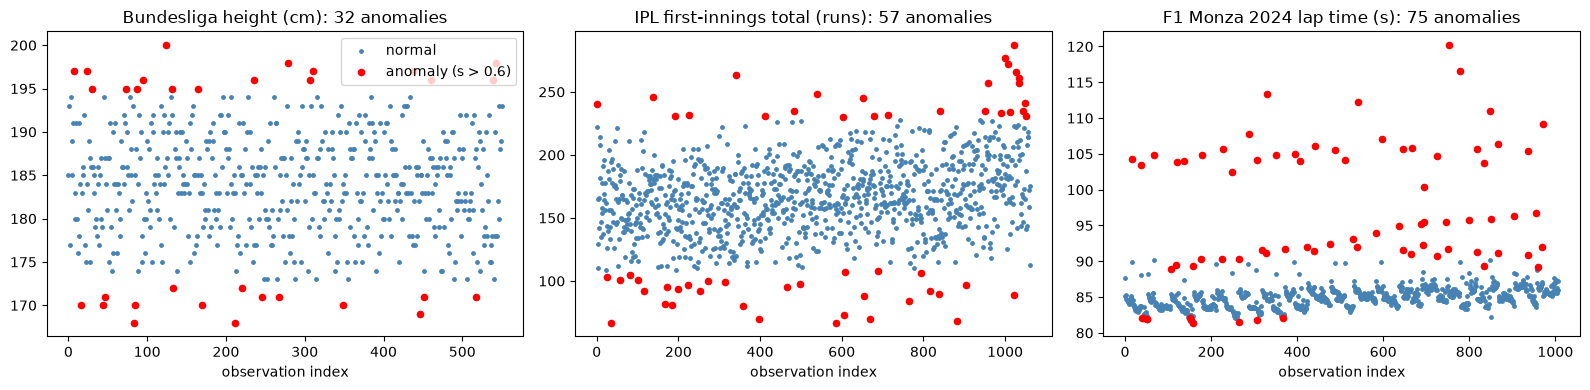

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, values) in zip(axes, datasets.items()):
    anom = if_anom[name]
    idx = np.arange(values.size)
    ax.scatter(idx[~anom], values[~anom], s=6, color="steelblue", label="normal")
    ax.scatter(idx[anom], values[anom], s=20, color="red", label="anomaly (s > 0.6)")
    ax.set_title(f"{name}: {anom.sum()} anomalies")
    ax.set_xlabel("observation index")

axes[0].legend()
plt.tight_layout()
plt.show()

## Interpretation

| Data set | 3σ | IQR | DBSCAN noise | Isolation Forest (s > 0.6) |
|---|---|---|---|---|
| Bundesliga height | 0 | 0 | 1 | 32 |
| IPL totals | 11 | 19 | 5 | 57 |
| F1 lap times | 31 | 74 | 7 | 75 |

**F1:** Isolation Forest found all 30 pit stops and Tsunoda's retirement lap. It also flagged lap 1 and the in- and out-laps. But it also flagged the fastest laps of the race (81 to 82 s). These are not real anomalies. They are just at the edge of the data.

**Heights and IPL:** Isolation Forest flags the values at both edges. For heights, these are normal values (the shortest and tallest players). Every other method found 0 or 1 anomalies here.

**Why:** Isolation Forest isolates points with random cuts. In one dimension, values at the edges are always isolated quickly, even in normal data. The method does not know which direction is unusual.

**Cutoff:** The default ("auto", s > 0.5) flagged 16 to 34% of the data. A higher cutoff reduces this, but at s > 0.7 most pit stops are missed, because the pit-stop laps lie close together and hide each other (masking). The cutoff has to be chosen with care, like eps in DBSCAN.

**Conclusion:** Isolation Forest works without any assumption about the distribution and found every real event in the F1 data. On one-dimensional data it produces many false alarms at the edges. It is better suited to data with many features.